
# GPS Stop & Dwell Time Analysis

## 1. Project Overview

This notebook analyzes synthetic GPS mobility data to identify stationary locations and calculate the time spent by individual devices at those locations.

### Objectives
- Detect stationary GPS stops.
- Calculate dwell time for each detected stop.
- Analyze stop patterns across multiple devices.
- Visualize dwell-time distributions and stop locations.
- Derive insights relevant to hyper-local retail mobility analytics.

### Dataset
- Source: `data/geopulse_stop_scenarios.csv`
- Devices: 20
- GPS records: 540
- Expected detected stops: 80

**Note:** This is synthetic GPS data generated for analytical and testing purposes. It does not represent actual customer movements.


In [1]:

# 2. Import Libraries and Project Configuration

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    raise FileNotFoundError(
        "Project root not found. Open Jupyter Notebook from the GeoPulse project directory."
    )

# Add source directory to Python path
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from geopulse.stops import detect_gps_stops

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Project Root:", PROJECT_ROOT)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Libraries imported successfully.")


Project Root: C:\Users\visha\OneDrive\Desktop\GeoPulse--Hyper-Local-Retail-Mobility-Analytics
Pandas Version: 3.0.3
NumPy Version: 2.4.6
Libraries imported successfully.



## 3. Load Synthetic GPS Dataset

Load the generated GPS stop scenario dataset from the project's data directory. The dataset contains GPS observations for multiple devices, including stationary locations and movement between stops.


In [2]:

# Load GPS stop scenario dataset

DATA_PATH = PROJECT_ROOT / "data" / "geopulse_stop_scenarios.csv"

gps_data = pd.read_csv(DATA_PATH)

# Convert Timestamp column into datetime format
gps_data["Timestamp"] = pd.to_datetime(gps_data["Timestamp"])

print("Dataset loaded successfully.")
print("Dataset Shape:", gps_data.shape)
print("Unique Devices:", gps_data["DeviceID"].nunique())

display(gps_data.head(10))


Dataset loaded successfully.
Dataset Shape: (540, 4)
Unique Devices: 20


,DeviceID,Lat,Long,Timestamp
0,D001,28.704802,77.137790,2026-11-20 08:00:00
1,D001,28.704762,77.137756,2026-11-20 08:05:00
2,D001,28.704793,77.137771,2026-11-20 08:10:00
3,D001,28.707791,77.140776,2026-11-20 08:15:00
4,D001,28.710791,77.143763,2026-11-20 08:20:00
5,D001,28.710804,77.143787,2026-11-20 08:25:00
6,D001,28.710792,77.143793,2026-11-20 08:30:00
7,D001,28.710798,77.143763,2026-11-20 08:35:00
8,D001,28.713791,77.146776,2026-11-20 08:40:00
9,D001,28.716797,77.149761,2026-11-20 08:45:00



## 4. Data Quality Assessment

Before performing stop detection, we examine the dataset for missing values, duplicate records, invalid GPS coordinates, and timestamp consistency.

These checks help ensure that the GPS observations are suitable for mobility analysis.


In [3]:

# Dataset structure and data types

print("Dataset Information:")
gps_data.info()

print("\nMissing Values:")
display(gps_data.isnull().sum())

print("\nDuplicate Records:", gps_data.duplicated().sum())

print("\nCoordinate Validation:")
print("Valid Latitude:", gps_data["Lat"].between(-90, 90).all())
print("Valid Longitude:", gps_data["Long"].between(-180, 180).all())

print("\nTimestamp Range:")
print("Start:", gps_data["Timestamp"].min())
print("End:", gps_data["Timestamp"].max())

print("\nDevice Count:", gps_data["DeviceID"].nunique())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 540 entries, 0 to 539
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   DeviceID   540 non-null    str           
 1   Lat        540 non-null    float64       
 2   Long       540 non-null    float64       
 3   Timestamp  540 non-null    datetime64[us]
dtypes: datetime64[us](1), float64(2), str(1)
memory usage: 19.1 KB

Missing Values:


DeviceID     0
Lat          0
Long         0
Timestamp    0
dtype: int64


Duplicate Records: 0

Coordinate Validation:
Valid Latitude: True
Valid Longitude: True

Timestamp Range:
Start: 2026-11-20 08:00:00
End: 2026-11-20 11:45:00

Device Count: 20



## 5. GPS Stop Detection

GPS stop detection identifies locations where a device remains within a specified geographic radius for a minimum duration.

The detection process uses:
- Stop radius: 100 meters
- Minimum dwell time: 10 minutes
- Maximum observation gap: 10 minutes

The algorithm processes each device independently and calculates the start time, end time, dwell duration, point count, and average stop coordinates.


In [4]:

# Apply GPS stop detection

stops_data = detect_gps_stops(
    gps_data,
    stop_radius_meters=100,
    min_dwell_minutes=10,
    max_gap_minutes=10,
)

print("GPS Stop Detection Completed")
print("Total GPS Records:", len(gps_data))
print("Total Detected Stops:", len(stops_data))
print("Unique Devices with Stops:", stops_data["DeviceID"].nunique())

display(stops_data.head(10))


GPS Stop Detection Completed
Total GPS Records: 540
Total Detected Stops: 80
Unique Devices with Stops: 20


,DeviceID,StopID,StartTime,EndTime,DwellMinutes,PointCount,Lat,Long
0,D001,D001_S001,2026-11-20 08:00:00,2026-11-20 08:10:00,10.0,3,28.704786,77.137772
1,D001,D001_S003,2026-11-20 08:20:00,2026-11-20 08:35:00,15.0,4,28.710796,77.143776
2,D001,D001_S005,2026-11-20 08:45:00,2026-11-20 09:15:00,30.0,7,28.716797,77.149773
3,D001,D001_S007,2026-11-20 09:25:00,2026-11-20 10:10:00,45.0,10,28.722796,77.155777
4,D002,D002_S001,2026-11-20 08:05:00,2026-11-20 08:15:00,10.0,3,28.707374,77.182973
5,D002,D002_S003,2026-11-20 08:25:00,2026-11-20 08:40:00,15.0,4,28.713379,77.188978
6,D002,D002_S005,2026-11-20 08:50:00,2026-11-20 09:20:00,30.0,7,28.719382,77.194969
7,D002,D002_S007,2026-11-20 09:30:00,2026-11-20 10:15:00,45.0,10,28.725380,77.200965
8,D003,D003_S001,2026-11-20 08:10:00,2026-11-20 08:20:00,10.0,3,28.603163,77.243836
9,D003,D003_S003,2026-11-20 08:30:00,2026-11-20 08:45:00,15.0,4,28.609177,77.249822



## 6. Dwell Time Analysis

Dwell time represents the observed duration between the first and last GPS observations of a detected stop.

This section examines the distribution of dwell times using descriptive statistics and identifies how long devices remain stationary at detected locations.


In [5]:

# Dwell-time descriptive statistics

dwell_summary = stops_data["DwellMinutes"].describe()

print("Dwell Time Statistical Summary:")
display(dwell_summary.to_frame(name="Dwell Minutes"))

print("\nAverage Dwell Time:",
      round(stops_data["DwellMinutes"].mean(), 2), "minutes")

print("Median Dwell Time:",
      stops_data["DwellMinutes"].median(), "minutes")

print("Total Observed Dwell Time:",
      stops_data["DwellMinutes"].sum(), "minutes")

print("\nDwell Duration Frequency:")
display(
    stops_data["DwellMinutes"]
    .value_counts()
    .sort_index()
    .rename_axis("Dwell Minutes")
    .to_frame("Number of Stops")
)


Dwell Time Statistical Summary:


,Dwell Minutes
count,80.000000
mean,25.000000
std,13.779456
min,10.000000
25%,13.750000
50%,22.500000
75%,33.750000
max,45.000000



Average Dwell Time: 25.0 minutes
Median Dwell Time: 22.5 minutes
Total Observed Dwell Time: 2000.0 minutes

Dwell Duration Frequency:


,Number of Stops
Dwell Minutes,
10.0,20
15.0,20
30.0,20
45.0,20



## 7. Dwell Time Visualization

Visualize the distribution of detected GPS stops across different dwell-time durations.

The histogram shows the frequency of stop durations, while the bar chart compares the number of stops in each dwell-time category.


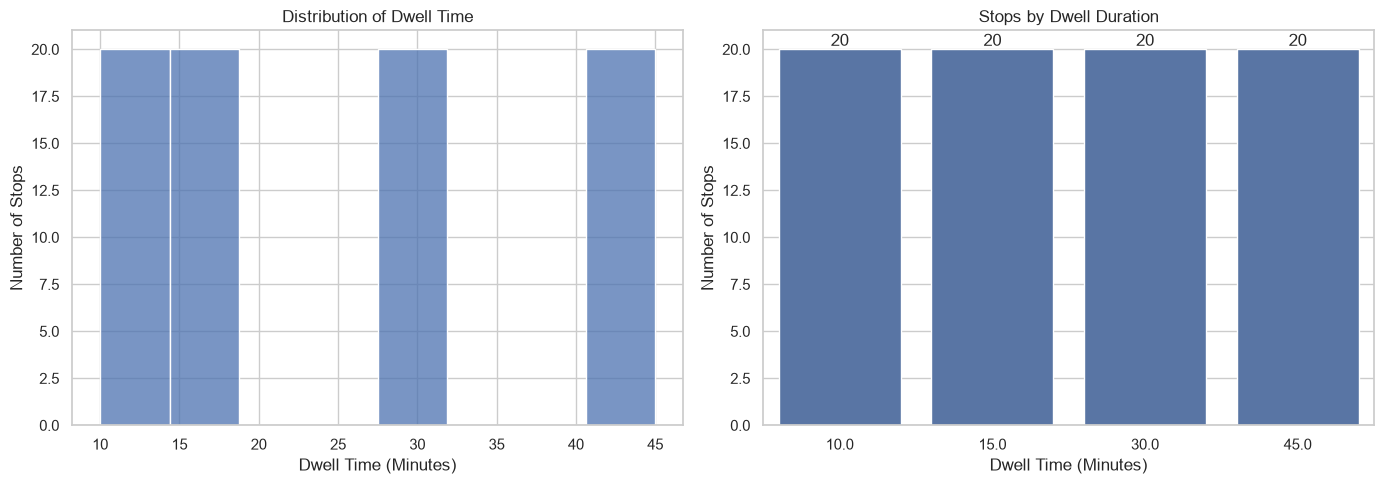

In [6]:

# Dwell-time distribution visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(
    data=stops_data,
    x="DwellMinutes",
    bins=8,
    kde=False,
    ax=axes[0]
)

axes[0].set_title("Distribution of Dwell Time")
axes[0].set_xlabel("Dwell Time (Minutes)")
axes[0].set_ylabel("Number of Stops")

# Category frequency bar chart
dwell_counts = (
    stops_data["DwellMinutes"]
    .value_counts()
    .sort_index()
)

sns.barplot(
    x=dwell_counts.index,
    y=dwell_counts.values,
    ax=axes[1]
)

axes[1].set_title("Stops by Dwell Duration")
axes[1].set_xlabel("Dwell Time (Minutes)")
axes[1].set_ylabel("Number of Stops")

for container in axes[1].containers:
    axes[1].bar_label(container)

plt.tight_layout()
plt.show()



## 8. Device-wise Stop Analysis

This section examines GPS stop activity for individual devices.

We calculate the total number of detected stops and average dwell time for each device to understand device-level mobility patterns.


In [7]:

# Device-wise stop summary

device_summary = (
    stops_data.groupby("DeviceID")
    .agg(
        TotalStops=("StopID", "count"),
        AverageDwellMinutes=("DwellMinutes", "mean"),
        TotalDwellMinutes=("DwellMinutes", "sum"),
        MaximumDwellMinutes=("DwellMinutes", "max"),
    )
    .reset_index()
)

device_summary = device_summary.sort_values(
    "TotalDwellMinutes",
    ascending=False
)

print("Device-wise Stop Summary:")
display(device_summary.head(10))

print("\nOverall Device Statistics:")
print("Total Devices:", len(device_summary))
print("Average Stops per Device:",
      round(device_summary["TotalStops"].mean(), 2))
print("Average Dwell Time per Device:",
      round(device_summary["AverageDwellMinutes"].mean(), 2))


Device-wise Stop Summary:


,DeviceID,TotalStops,AverageDwellMinutes,TotalDwellMinutes,MaximumDwellMinutes
0,D001,4,25.0,100.0,45.0
1,D002,4,25.0,100.0,45.0
2,D003,4,25.0,100.0,45.0
3,D004,4,25.0,100.0,45.0
4,D005,4,25.0,100.0,45.0
5,D006,4,25.0,100.0,45.0
6,D007,4,25.0,100.0,45.0
7,D008,4,25.0,100.0,45.0
8,D009,4,25.0,100.0,45.0
9,D010,4,25.0,100.0,45.0



Overall Device Statistics:
Total Devices: 20
Average Stops per Device: 4.0
Average Dwell Time per Device: 25.0



## 9. Device-wise Stop Visualization

Visualize the number of detected stops and total dwell time for each device.

These comparisons help identify differences in device-level stop activity and overall observed dwell duration.


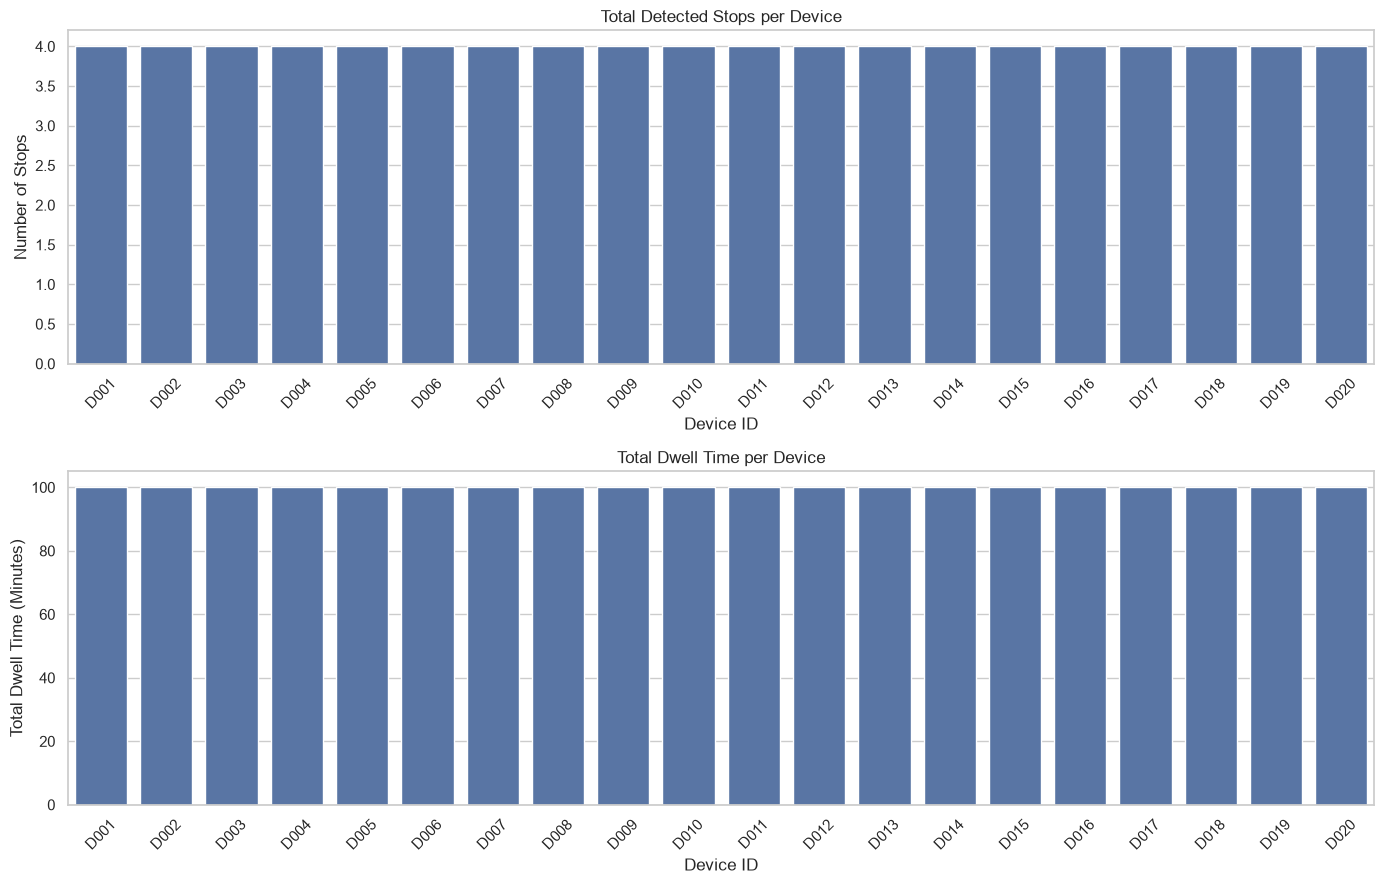

In [8]:

# Device-wise activity visualization

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Total stops per device
sns.barplot(
    data=device_summary,
    x="DeviceID",
    y="TotalStops",
    ax=axes[0]
)

axes[0].set_title("Total Detected Stops per Device")
axes[0].set_xlabel("Device ID")
axes[0].set_ylabel("Number of Stops")
axes[0].tick_params(axis="x", rotation=45)

# Total dwell time per device
sns.barplot(
    data=device_summary,
    x="DeviceID",
    y="TotalDwellMinutes",
    ax=axes[1]
)

axes[1].set_title("Total Dwell Time per Device")
axes[1].set_xlabel("Device ID")
axes[1].set_ylabel("Total Dwell Time (Minutes)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()



## 10. Geographical Stop Location Analysis

This section visualizes the geographical distribution of detected GPS stops using latitude and longitude coordinates.

Each point represents a detected stop location. The color intensity indicates the dwell duration, helping identify locations associated with longer stationary observations.


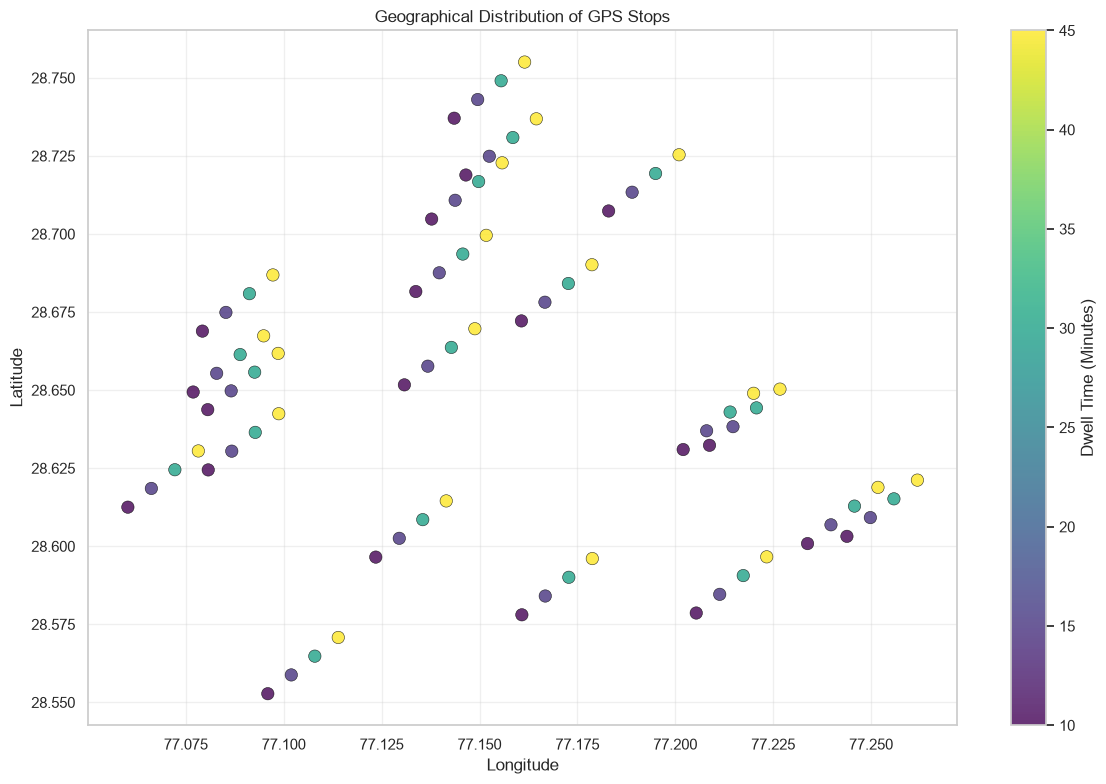

In [9]:

# Geographical distribution of detected stops

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    stops_data["Long"],
    stops_data["Lat"],
    c=stops_data["DwellMinutes"],
    cmap="viridis",
    s=80,
    alpha=0.8,
    edgecolors="black",
    linewidths=0.4
)

plt.colorbar(
    scatter,
    label="Dwell Time (Minutes)"
)

plt.title("Geographical Distribution of GPS Stops")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## 11. Business Insights

The GPS stop and dwell-time analysis provides the following observations:

1. **Stop Identification:** The system successfully detected 80 stationary stops from 540 GPS observations across 20 devices.

2. **Dwell Time:** The average dwell time was 25 minutes, indicating the observed duration devices remained at detected locations.

3. **Long-Duration Stops:** A total of 20 stops had a dwell time of 45 minutes. These locations represent longer stationary observations.

4. **Device Activity:** Each device generated four detected stops, with an average total dwell time of 100 minutes.

5. **Geographical Distribution:** The detected stop coordinates show multiple spatial clusters that can be further analyzed alongside retail store locations.

6. **Retail Application:** Stop locations and dwell durations can support retail catchment analysis, potential customer engagement studies, and location-based retail planning.

**Note:** The dataset is synthetic. These observations demonstrate the analytical workflow and should not be interpreted as actual customer behaviour or validated retail demand.

---

## 12. Conclusion

This analysis successfully implemented GPS stop detection and dwell-time measurement using synthetic mobility data.

A total of 540 GPS observations from 20 devices were processed, resulting in 80 detected stops. The analysis examined dwell-time distributions, device-wise activity, and geographical stop locations.

The results demonstrate how GPS mobility data can be processed to identify stationary locations and measure observed dwell duration. This functionality provides a foundation for further hyper-local retail mobility and spatial analytics.
